# Сравнение алгоритмов
## Результаты лабораторных работ 1–5

Здесь я собираю результаты всех лабораторных, чтобы сравнить алгоритмы на одинаковых задачах.
Сейчас выполнены **№1 — KNN** и **№2 — логистическая и линейная регрессия**.
После следующих работ таблицы и графики будут дополнены.

| Задача | Данные | Основной показатель |
|:--|:--|:--|
| Одобрение кредитной заявки | Loan Approval | F1: больше — лучше |
| Прочность бетона | Concrete Strength | MAE, МПа: меньше — лучше |

Во всех работах использую одинаковые исходные данные и разбиения train/test.
Для бетона сохраняю разделение по рецептурам. Параметры выбираю по CV на train,
а здесь сравниваю итоговые результаты на test.

---

### Что именно сравнивается

Классификация — предварительное одобрение заявки (`loan_status`: 1 — одобрено, 0 — отказ)
по 12 признакам клиента и запроса, без процентной ставки.
Регрессия — прочность `strength` в МПа по восьми признакам состава и возраста бетона.
F1 учитывает precision и recall при дисбалансе классов; MAE — средняя абсолютная ошибка прочности.

### Условия эксперимента

| Параметр | Классификация | Регрессия |
|:--|:--|:--|
| Train / test | 36 000 / 9 000 заявок | 799 / 206 измерений |
| Разбиение | 80/20, со стратификацией | 80/20 по рецептурам, GroupShuffleSplit |
| Кросс-валидация | StratifiedKFold(3), shuffle=True | GroupKFold(3) по рецептурам |
| Случайное состояние | 42 | 42 |
| Выбор параметров | Максимум среднего F1 на train-CV | Минимум средней MAE на train-CV |

Рецептура — совпадение количеств всех семи компонентов смеси; возраст и прочность
не входят в ключ группы. Поэтому одна смесь в разных возрастах не пересекает train/test
и обучающие/валидационные части CV. Доля строк test для бетона составляет около 20,5%,
поскольку разделяются группы, а не отдельные измерения.

Все оценки CV считаю на полном train. Заполнение пропусков, кодирование и масштабирование
обучаются внутри каждого фолда. EDA использует только train. После выбора настроек
переобучаю модель на полном train и один раз оцениваю каждый зафиксированный вариант на test.
По результатам test параметры не меняю. Повторный поиск на одних CV-фолдах может завышать
оценку победившей конфигурации, поэтому отдельно показываю и CV, и test.


Для каждой работы сравниваю четыре варианта: исходный и улучшенный sklearn,
исходную и улучшенную свою модель. Внутри одной работы преобразования и параметры
библиотечной и своей моделей совпадают. Между работами предобработка может различаться:
это часть исследуемого решения. Время включает преобразования, обучение или прогноз,
но не поиск параметров по CV; оно измерено одним запуском на текущей машине.


## 1. Результаты выполненных работ

Загружу сохранённые метрики. Отдельно покажу, какие лабораторные уже включены в сравнение.

In [1]:
# Ноутбук можно открыть из корня или каталога любой лабораторной.
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Общий стиль таблиц и графиков.
MODEL_NAMES = {
    "sklearn_baseline": "sklearn · исходная",
    "sklearn_improved": "sklearn · улучшенная",
    "custom_baseline": "своя · исходная",
    "custom_improved": "своя · улучшенная",
    "dummy": "Dummy",
}
TASK_NAMES = {"classification": "Классификация", "regression": "Регрессия"}
COLUMN_NAMES = {
    "model": "Модель", "task": "Задача", "lab": "Работа", "dataset": "Набор данных",
    "algorithm": "Алгоритм", "implementation": "Реализация", "stage": "Вариант",
    "f1": "F1 ↑", "precision": "Precision", "recall": "Recall",
    "accuracy": "Accuracy", "balanced_accuracy": "Balanced accuracy",
    "roc_auc": "ROC-AUC", "average_precision": "AP", "mae": "MAE, МПа ↓",
    "rmse": "RMSE, МПа ↓", "r2": "R² ↑", "fit_seconds": "Обучение, с",
    "predict_seconds": "Прогноз, с", "mode": "Признаки", "representation": "Признаки",
    "cv_mean": "Среднее CV", "cv_std": "Разброс CV", "mean_test_score": "Среднее CV",
    "std_test_score": "Разброс CV", "rank_test_score": "Место", "status": "Статус",
    "comparison": "Сравнение", "delta": "Изменение", "metric": "Метрика",
    "estimator": "Алгоритм", "n_iter": "Итерации", "gradient_norm": "Норма градиента",
    "objective": "Функция потерь", "missing_train": "Пропуски", "dtype": "Тип",
    "missing": "Пропуски", "unique": "Уникальные", "type": "Тип",
    "param_model__n_neighbors": "Соседи (k)", "param_model__weights": "Веса",
    "param_model__p": "Расстояние (p)", "class_weight": "Веса классов",
    "count": "Количество", "fraction": "Доля", "train_fraction": "Доля в train",
}

def show_table(value, title=None):
    """Вывод таблицы с подписями и одинаковой точностью чисел."""
    if isinstance(value, pd.Series):
        value = value.to_frame()
    if not isinstance(value, pd.DataFrame):
        display(value)
        return
    table = value.copy()
    for column in table.columns:
        table[column] = table[column].map(
            lambda item: MODEL_NAMES.get(item, TASK_NAMES.get(item, item)) if isinstance(item, str) else item)
    table = table.rename(columns=COLUMN_NAMES)
    styled = table.style.format(precision=4, na_rep="—").set_table_styles([
        {"selector": "th", "props": [("background-color", "#edf3f8"), ("color", "#243b53"),
                                     ("padding", "9px 12px"), ("text-align", "left")]},
        {"selector": "td", "props": [("padding", "7px 12px"), ("border-bottom", "1px solid #e8edf2")]},
        {"selector": "caption", "props": [("caption-side", "top"), ("text-align", "left"),
                                          ("font-weight", "600"), ("padding", "10px 0")]},
    ])
    if isinstance(table.index, pd.RangeIndex):
        styled = styled.hide(axis="index")
    if title:
        styled = styled.set_caption(title)
    if "Норма градиента" in table.columns:
        styled = styled.format({"Норма градиента": "{:.2e}"})
    display(styled)

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "grid.alpha": 0.25, "axes.prop_cycle": plt.cycler(color=["#387ca3", "#db9655", "#4c9c8a", "#9c7cb5"]),
})

ROOT =Path.cwd() if (Path.cwd() / "lab_1").is_dir() else Path.cwd().parent
required = {"lab", "algorithm", "model", "implementation", "stage", "task", "dataset", "target", "feature_set",
            "dataset_sha", "split_sha", "protocol_id", "n_train", "n_test", "fit_seconds", "predict_seconds"}
frames, status = [], []
for number in range(1, 6):
    file = ROOT / f"lab_{number}" / "results" / "metrics.csv"
    status.append({"lab": number, "status": "результаты доступны" if file.exists() else "результаты отсутствуют"})
    if file.exists():
        frame = pd.read_csv(file)
        if not required.issubset(frame.columns):
            raise ValueError(f"Неполная схема {file}: {required - set(frame.columns)}")
        if frame.empty or not frame.lab.eq(number).all():
            raise ValueError(f"Некорректные строки в {file}")
        frames.append(frame)
show_table(pd.DataFrame(status))
if not frames:
    raise RuntimeError("Файлы результатов отсутствуют")
results = pd.concat(frames, ignore_index=True)
assert not results.duplicated(["lab", "task", "model"]).any()
print(f"Получено {len(results)} строк; лабораторных: {results.lab.nunique()} из 5")

Работа,Статус
1,результаты доступны
2,результаты доступны
3,результаты отсутствуют
4,результаты отсутствуют
5,результаты отсутствуют


Получено 20 строк; лабораторных: 2 из 5


## 2. Сравнение качества

Сначала проверю, что совпадают данные, цель и разбиения.
Затем сравню исходные и улучшенные модели sklearn и свои реализации.
Dummy служит простым ориентиром, от которого стоит отталкиваться.

| Работа и задача | Исходный вариант | Улучшенный вариант |
|:--|:--|:--|
| №1 · классификация | KNN: k=5, p=2, uniform, без scaling | StandardScaler и log1p дохода; k=15, p=1, distance |
| №1 · регрессия | KNN: k=5, p=2, uniform, без scaling | StandardScaler, log1p возраста, признаки состава; k=5, p=2, distance |
| №2 · классификация | StandardScaler, LogisticRegression: C=1, обычные веса | Log-признаки, отношения, полиномы степени 2; C=0,1, обычные веса |
| №2 · регрессия | StandardScaler, LinearRegression без штрафа | Log-признаки, отношения, полиномы степени 2; Ridge alpha=1 |

В №1 категории кодируются полным one-hot, в №2 — one-hot с удалением первого уровня.
Логистическая регрессия использует фиксированный порог 0,5.
Dummy всегда выбирает наиболее частый класс или медиану прочности.


In [2]:
# Сначала проверяем протокол внутри каждой задачи, затем показываем результаты.
identity = ["dataset", "target", "feature_set", "dataset_sha", "split_sha", "protocol_id", "n_train", "n_test"]
for task, group in results.groupby("task"):
    if len(group[identity].drop_duplicates()) != 1:
        raise ValueError(f"Несопоставимые данные или разбиения для {task}")
    score = "f1" if task == "classification" else "mae"
    if score not in group or group[score].isna().any():
        raise ValueError(f"Отсутствуют метрики для {task}")
    columns = ["lab", "algorithm", "model"]
    columns += ["f1", "precision", "recall", "balanced_accuracy", "accuracy", "roc_auc", "average_precision"] if task == "classification" else ["mae", "rmse", "r2"]
    columns += ["fit_seconds", "predict_seconds"]
    print(TASK_NAMES[task])
    show_table(group[columns].sort_values(score, ascending=task != "classification").round(5))

Классификация


,Работа,Алгоритм,Модель,F1 ↑,Precision,Recall,Balanced accuracy,Accuracy,ROC-AUC,AP,"Обучение, с","Прогноз, с"
12,2,LogisticRegression,sklearn · улучшенная,0.7157,0.7702,0.6685,0.8057,0.8820,0.9403,0.8256,0.1778,0.0170
14,2,LogisticRegression,своя · улучшенная,0.7157,0.7702,0.6685,0.8057,0.8820,0.9403,0.8256,0.2191,0.0169
2,1,KNN,sklearn · улучшенная,0.6960,0.7907,0.6215,0.7873,0.8793,0.9352,0.8303,0.0429,3.2308
4,1,KNN,своя · улучшенная,0.6960,0.7907,0.6215,0.7873,0.8793,0.9352,0.8303,0.0448,37.7718
11,2,LogisticRegression,sklearn · исходная,0.6929,0.7355,0.6550,0.7939,0.8710,0.9361,0.8148,0.0796,0.0106
13,2,LogisticRegression,своя · исходная,0.6929,0.7355,0.6550,0.7939,0.8710,0.9361,0.8148,0.0968,0.0106
3,1,KNN,своя · исходная,0.5859,0.6669,0.5225,0.7240,0.8359,0.8147,0.5943,0.0431,38.6559
1,1,KNN,sklearn · исходная,0.5859,0.6669,0.5225,0.7240,0.8359,0.8147,0.5943,0.0420,0.8483
0,1,Dummy,Dummy,0.0000,0.0000,0.0000,0.5000,0.7778,0.5000,0.2222,0.0421,0.0071
10,2,Dummy,Dummy,0.0000,0.0000,0.0000,0.5000,0.7778,0.5000,0.2222,0.0462,0.0096


Регрессия


,Работа,Алгоритм,Модель,"MAE, МПа ↓","RMSE, МПа ↓",R² ↑,"Обучение, с","Прогноз, с"
7,1,KNN,sklearn · улучшенная,4.4187,6.7924,0.8570,0.0042,0.0027
9,1,KNN,своя · улучшенная,4.4218,6.7929,0.8570,0.0037,0.0076
19,2,LinearRegression,своя · улучшенная,4.8704,7.1397,0.8420,0.0063,0.0024
17,2,LinearRegression,sklearn · улучшенная,4.8704,7.1397,0.8420,0.0071,0.0024
8,1,KNN,своя · исходная,6.6675,9.1470,0.7407,0.0023,0.0056
6,1,KNN,sklearn · исходная,6.6675,9.1470,0.7407,0.0025,0.0018
16,2,LinearRegression,sklearn · исходная,8.6781,10.7918,0.6391,0.0034,0.0013
18,2,LinearRegression,своя · исходная,8.6781,10.7918,0.6391,0.0031,0.0013
15,2,Dummy,Dummy,14.5233,18.1552,-0.0215,0.0034,0.0013
5,1,Dummy,Dummy,14.5233,18.1552,-0.0215,0.0028,0.0011


### Качество на графиках

Цвет показывает вариант модели. Для классификации лучше более длинный столбец F1,
для регрессии — более короткий столбец MAE. Числа возле столбцов позволяют
сравнить близкие результаты.

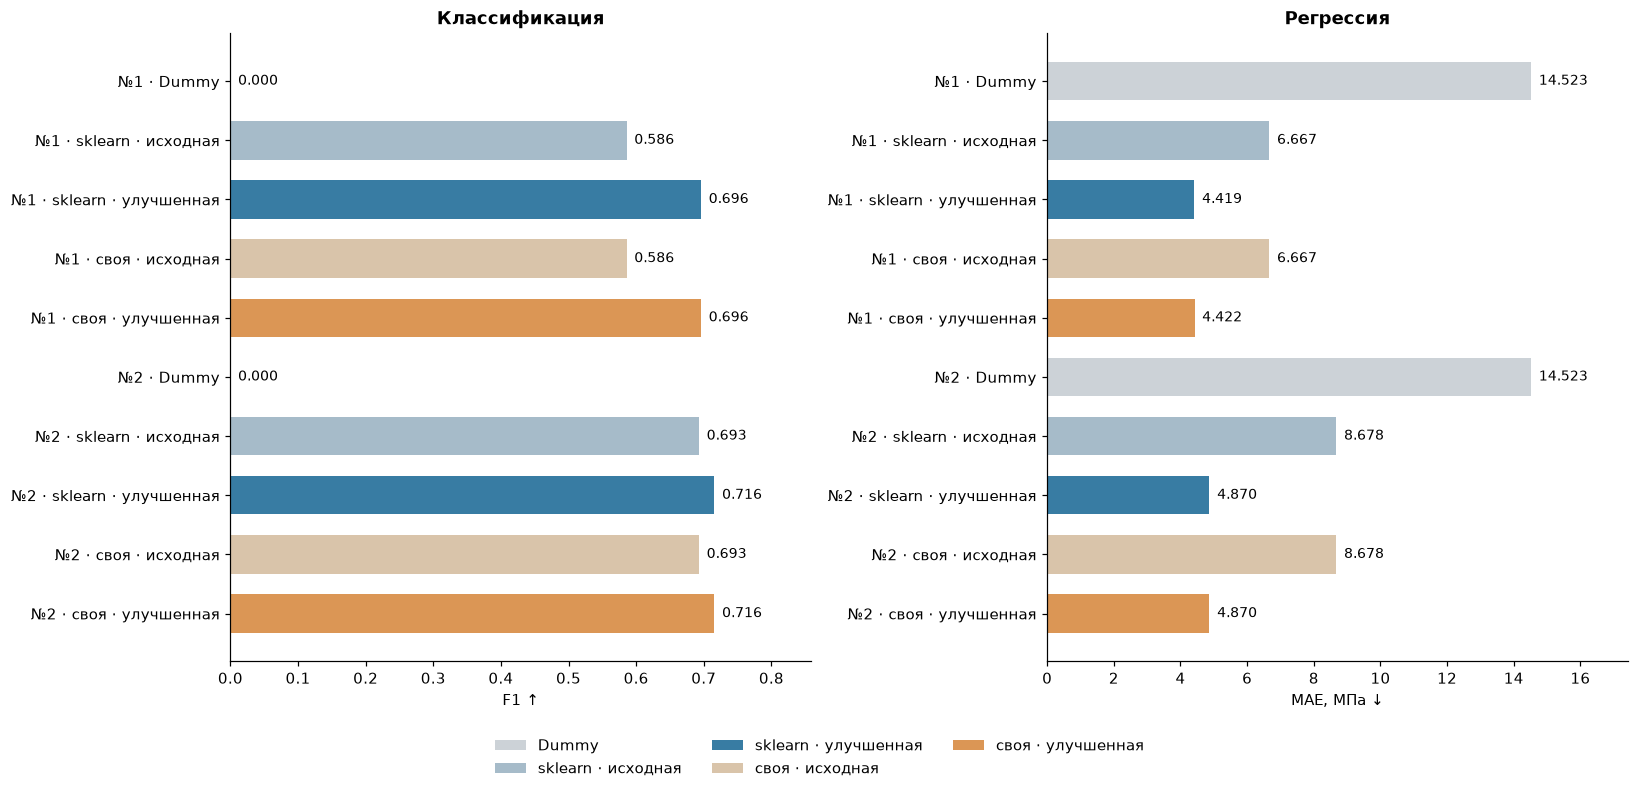

In [3]:
# Цвета вариантов одинаковы на обоих графиках.
from matplotlib.patches import Patch
colors = {"dummy": "#ccd2d7", "sklearn_baseline": "#a6bbc9", "sklearn_improved": "#387ca3",
          "custom_baseline": "#d9c4aa", "custom_improved": "#db9655"}
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, task, score in zip(axes, ["classification", "regression"], ["f1", "mae"]):
    group = results[results.task == task].copy()
    labels = [f"№{row.lab} · {MODEL_NAMES.get(row.model, row.model)}" for row in group.itertuples()]
    bars = ax.barh(labels, group[score], color=[colors.get(name, "#387ca3") for name in group.model], height=.65)
    ax.bar_label(bars, fmt="%.3f", padding=5, fontsize=9)
    ax.set(title=TASK_NAMES[task], xlabel="F1 ↑" if score == "f1" else "MAE, МПа ↓")
    ax.set_xlim(0, group[score].max() * 1.20)
    ax.invert_yaxis()
fig.legend(handles=[Patch(facecolor=color, label=MODEL_NAMES[name]) for name, color in colors.items()],
           loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(.5, -.035))
plt.tight_layout(rect=(0, .05, 1, 1))
plt.show()

## 3. Что дали улучшения

Посмотрю на разницу между исходными и улучшенными моделями,
а также между своей реализацией и sklearn при одинаковых настройках.
Для F1 хорошо положительное изменение, для MAE — отрицательное.

In [4]:
# Разности показывают эффект улучшений и совпадение качества реализаций.
pairs = [("sklearn_improved", "sklearn_baseline", "Улучшение sklearn"),
         ("custom_baseline", "sklearn_baseline", "Своя и sklearn: исходные"),
         ("custom_improved", "sklearn_improved", "Своя и sklearn: улучшенные"),
         ("custom_improved", "custom_baseline", "Улучшение своей модели")]
deltas = []
for (lab, task), group in results.groupby(["lab", "task"]):
    metric = "f1" if task == "classification" else "mae"
    group = group.set_index("model")
    for left, right, label in pairs:
        if left in group.index and right in group.index:
            deltas.append({"lab": lab, "task": task, "Метрика": "F1" if metric == "f1" else "MAE, МПа",
                           "comparison": label, "delta": group.loc[left, metric] - group.loc[right, metric]})
show_table(pd.DataFrame(deltas))

Работа,Задача,Метрика,Сравнение,Изменение
1,Классификация,F1,Улучшение sklearn,0.1100
1,Классификация,F1,Своя и sklearn: исходные,0.0000
1,Классификация,F1,Своя и sklearn: улучшенные,0.0000
1,Классификация,F1,Улучшение своей модели,0.1100
1,Регрессия,"MAE, МПа",Улучшение sklearn,-2.2488
1,Регрессия,"MAE, МПа",Своя и sklearn: исходные,0.0000
1,Регрессия,"MAE, МПа",Своя и sklearn: улучшенные,0.0030
1,Регрессия,"MAE, МПа",Улучшение своей модели,-2.2457
2,Классификация,F1,Улучшение sklearn,0.0228
2,Классификация,F1,Своя и sklearn: исходные,0.0000


## 4. Итоги сравнения

Ниже собраны изменения основных метрик. Отдельно сравню улучшенные модели sklearn
между работами, чтобы увидеть, какой алгоритм лучше подошёл каждой задаче.

In [5]:
# В итоговую таблицу возьму улучшенные модели sklearn каждой работы.
final_rows = []
for lab, group in results[(results.implementation == "sklearn") & (results.stage == "improved")].groupby("lab"):
    classification = group[group.task == "classification"]
    regression = group[group.task == "regression"]
    if not classification.empty and not regression.empty:
        c, r = classification.iloc[0], regression.iloc[0]
        final_rows.append({"Работа": f"№{lab}", "Алгоритмы": "KNN" if lab == 1 else "Логистическая / линейная регрессия" if lab == 2 else str(c.algorithm),
                           "F1 ↑": c.f1, "MAE, МПа ↓": r.mae, "RMSE, МПа ↓": r.rmse, "R² ↑": r.r2})
show_table(pd.DataFrame(final_rows), "Итоговое сравнение на одинаковом test")

Работа,Алгоритмы,F1 ↑,"MAE, МПа ↓","RMSE, МПа ↓",R² ↑
№1,KNN,0.6960,4.4187,6.7924,0.8570
№2,Логистическая / линейная регрессия,0.7157,4.8704,7.1397,0.8420


### Выводы

В классификации лучшей оказалась логистическая регрессия с полиномиальными признаками:
её F1 равен **0,71574**, у улучшенного KNN — **0,69597**.

У логистической регрессии recall выше: **66,85% против 62,15%**, но precision немного ниже: **77,02% против 79,07%**. Поэтому выигрыш по F1 связан с тем, что она находит больше одобренных заявок, хотя доля верных ответов среди предсказанных одобрений немного уменьшается.

Для прогноза прочности бетона лучше сработал KNN:
**MAE 4,419 МПа** против **4,870 МПа** у улучшенной линейной регрессии.
Таким образом, на этих двух задачах результаты различаются: лучшего алгоритма сразу
для классификации и регрессии нет.

В обеих работах предобработка и подбор параметров улучшили исходные модели.
Собственные реализации дали близкое к sklearn качество. Небольшое расхождение KNN
в регрессии связано с выбором соседа при практически равных расстояниях.

При сравнении времени нужно помнить, что KNN в основном запоминает train,
а поиск соседей выполняет при прогнозе. Линейные модели тратят время на подбор
коэффициентов, зато предсказание сводится к вычислению линейной комбинации.

Этот вывод относится к одному test. Для уверенного выбора алгоритма я бы повторил
сравнение на других разбиениях или использовал вложенную кросс-валидацию.

**Источники данных:** [Loan Approval, taweilo, Kaggle](https://www.kaggle.com/datasets/taweilo/loan-approval-classification-data)
и [Concrete Strength, Yeh (1998), UCI](https://doi.org/10.24432/C5PK67).
Кредитный набор синтетический, поэтому выводы о качестве относятся прежде всего к этому набору.
Для бетона отсутствие совпадающих рецептур между train/test не означает полной независимости близких смесей.
Работы №3–5 ещё не выполнены; их результаты будут добавлены в эту же сводку.

Для просмотра все таблицы и графики уже сохранены. Для повторного построения сводки
нужны `lab_1/results/metrics.csv` и `lab_2/results/metrics.csv`;
если появятся результаты следующих работ, код также включит их в сравнение.
